
### Choosing the Prior Parameters

Since the exercise does not provide specific values for $\alpha$ and $\beta$, we choose a weakly informative Gamma prior:

$$
\alpha = 1,\qquad \beta = 0.1
$$

The prior mean is:

$$
E[\lambda] = \frac{\alpha}{\beta} = 10
$$

The prior variance is:

$$
Var(\lambda) = \frac{\alpha}{\beta^2} = 100
$$

This prior represents an initial estimate of 10 calls per hour, with considerable uncertainty.


In [82]:
# Prior parameters
alpha = 1
beta = 0.1

# Prior mean and variance
prior_mean = alpha / beta
prior_variance = alpha / (beta ** 2)

print("Prior mean:", prior_mean)

Prior mean: 10.0



## Posterior Distribution

Using Bayes' theorem:

$$
p(\lambda \mid data) \propto p(data \mid \lambda)\,p(\lambda)
$$

Since the Gamma distribution is conjugate to the Poisson likelihood, the posterior distribution is also Gamma.

For 180 observed calls over 10 hours:

$$
\lambda \mid data \sim \operatorname{Gamma}(\alpha + 180,\beta + 10)
$$

Using our chosen prior parameters:

$$
\boxed{\lambda \mid data \sim \operatorname{Gamma}(181,10.1)}
$$

The posterior parameters are updated by adding the total number of observed calls to $\alpha$ and the total observation time to $\beta$.


In [83]:
total_calls = 180   
hours = 10

# Posterior parameters
posterior_alpha = alpha + total_calls
posterior_beta = beta + hours

# Posterior mean
posterior_mean = posterior_alpha / posterior_beta

print("Posterior alpha:", posterior_alpha)
print("Posterior beta:", posterior_beta)
print("Posterior mean:", posterior_mean)


Posterior alpha: 181
Posterior beta: 10.1
Posterior mean: 17.92079207920792



## Most Probable Value of Lambda

The most probable value of lambda is the mode of the posterior distribution, also called the Maximum A Posteriori (MAP) estimate.

For a Gamma distribution, the mode is:

$$
\lambda_{MAP} = \frac{\alpha_{posterior}-1}{\beta_{posterior}}
$$


In [84]:

# Calculate the most probable value of lambda
posterior_mode = (posterior_alpha - 1) / posterior_beta

print("Most probable value of lambda:", posterior_mode)


Most probable value of lambda: 17.821782178217823



## 94% Highest Density Interval (HDI)

The Highest Density Interval (HDI) is the interval containing 94% of the posterior probability, including the values with the highest probability density.

We use ArviZ to calculate the 94% HDI of the posterior distribution.


In [85]:
%pip install arviz

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [86]:
import numpy as np
import matplotlib.pyplot as plt
import arviz as az
from scipy.stats import gamma

# Generate samples from the posterior Gamma distribution
posterior_samples = gamma.rvs(
    a=posterior_alpha,
    scale=1 / posterior_beta,
    size=100000,
    random_state=42
)

# Calculate the 94% HDI
hdi = az.hdi(posterior_samples, prob=0.94)

print("94% HDI:", hdi)


94% HDI: [15.45980853 20.44630674]



## Posterior Distribution Visualization

We use ArviZ to visualize the posterior distribution of $\lambda$.

The plot shows the 94% Highest Density Interval (HDI) and the posterior mode (MAP), which represents the most probable value of $\lambda$.


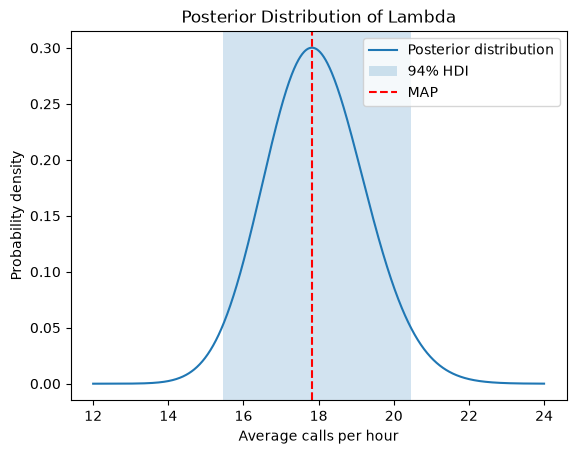

In [87]:

# Values for the posterior distribution
x = np.linspace(12, 24, 1000)
y = gamma.pdf(x, a=posterior_alpha, scale=1 / posterior_beta)

# Plot the posterior distribution
plt.plot(x, y, label="Posterior distribution")

# Highlight the 94% HDI
plt.axvspan(hdi[0], hdi[1], alpha=0.2, label="94% HDI")

# Show the most probable value
plt.axvline(posterior_mode, color="red", linestyle="--", label="MAP")

plt.title("Posterior Distribution of Lambda")
plt.xlabel("Average calls per hour")
plt.ylabel("Probability density")
plt.legend()
plt.show()
